# M9a · UADFV preprocessing for cross-dataset testing (face crops)

**Goal.** Turn the UADFV videos into face crops made exactly like our FF++ training crops (M0) and the DFD crops (M8a), so M9b can score the existing FF++-trained checkpoints on UADFV. No training here.

**Why UADFV.** LNCLIP-DF / GenD (Yermakov et al., WACV 2026) tests FF++-trained models on UADFV (Yang, Li, Lyu, ICASSP 2019) and reports video AUC **99.2** for GenD-CLIP (Table 4, mean of 5 seeds). UADFV has 49 real YouTube videos and 49 fakes; each fake is made from the real video with the same number. It is small and old (2018 DeepFake method, low resolution), so it is the easiest dataset in the paper's table.

**Pipeline (same as M8a):**

| step | setting |
|---|---|
| frames | 32 evenly spaced frames decoded from the video, then a JPEG round trip with the settings M8a measured on `frames_all` (read from `faces_dfd/pipeline.json`) |
| face detector | MTCNN, largest face with prob ≥ 0.9, missing frames take the nearest detected box |
| crop | 1.3× square box, 224×224, PNG |
| fakes | detected independently per video |

**Inputs (read only):** `uadfv/` (videos), `faces_dfd/pipeline.json` (JPEG settings from M8a).
**Outputs:** `DATA_ROOT/faces_uadfv/`, `DATA_ROOT/index/uadfv.csv`, `DATA_ROOT/runs/m9a/`.

| Section | What it does | Run time |
|---|---|---|
| 1 | settings, imports, environment | seconds |
| 2 | inventory: find and label the videos, read video metadata | seconds |
| 3 | JPEG settings (reused from M8a) | seconds |
| 4 | face extraction: helpers, smoke test, full run (resumable) | ~2–5 min |
| 5 | extraction status, failures, faces per frame | seconds |
| 6 | build the index CSV, summary, example crops | seconds |

## 1. Setup

### 1.1 Paths and settings

Crop settings are copied from M0/M8a and must not be changed, otherwise UADFV crops would differ from the training crops.

In [1]:
# 1.1 Paths and settings
from pathlib import Path

# inputs (read only)
UADFV_ROOT = Path("/nlsasfs/home/isea/isea64/uadfv")
REAL_DIR = UADFV_ROOT / "real" / "real"
FAKE_DIR = UADFV_ROOT / "fake" / "fake"

# outputs (ours)
DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
M8A_PIPELINE = DATA_ROOT / "faces_dfd" / "pipeline.json"
FACES_ROOT = DATA_ROOT / "faces_uadfv"
INDEX_CSV = DATA_ROOT / "index" / "uadfv.csv"
RUN_DIR = DATA_ROOT / "runs" / "m9a"

EXPECTED_REAL, EXPECTED_FAKE = 49, 49
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv"}

# same as M0 / M8a
FRAMES_PER_VIDEO = 32
CROP_SCALE = 1.3
IMAGE_SIZE = 224
IMAGE_FORMAT = "png"
MIN_FACE_PROB = 0.9
DETECTOR_BATCH = 16

LOAD_WORKERS = 8
META_WORKERS = 16
RETRY_FAILED = False     # True = retry videos marked as failed (no face / unreadable) in an earlier run
SEED = 0

assert REAL_DIR.is_dir() and FAKE_DIR.is_dir(), (REAL_DIR, FAKE_DIR)
assert M8A_PIPELINE.exists(), f"run M8a first: {M8A_PIPELINE}"
for d in (FACES_ROOT, INDEX_CSV.parent, RUN_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("outputs go to:", FACES_ROOT, "|", INDEX_CSV, "|", RUN_DIR)

outputs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/faces_uadfv | /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/index/uadfv.csv | /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m9a


### 1.2 Imports and environment

In [2]:
# 1.2 Imports and environment
import io, json, os, platform, random, re, sys, time
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version
from itertools import islice

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm
from facenet_pytorch import MTCNN

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "opencv": cv2.__version__,
    "facenet-pytorch": version("facenet-pytorch"),
    "pillow": Image.__version__,
    "GPU": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
}
display(pd.Series(env, name="value").to_frame())
(RUN_DIR / "environment.json").write_text(json.dumps(env, indent=2))

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
python,3.10.12
torch,2.6.0+cu124
opencv,5.0.0
facenet-pytorch,2.6.0
pillow,12.3.0
GPU,NVIDIA A100-SXM4-40GB


158

## 2. Inventory

Labels come from the folder (`real/real` = 0, `fake/fake` = 1). `pair_id` is the leading number of the file name; a fake and the real video it was made from share it (e.g. `0000.mp4` and `0000_fake.mp4`). M9b resamples these pairs in the bootstrap.

Your listing showed 51 entries per folder against 49 official videos, so every entry that is not a video is printed here. Expected: 49 real and 49 fake videos, 0 duplicate ids, every fake paired with a real video. If the video counts differ, the cell stops; send me its output.

In [3]:
# 2.1 Find and label the videos
rows, other = [], {}
for label, folder in ((0, REAL_DIR), (1, FAKE_DIR)):
    entries = sorted(folder.iterdir())
    other[folder.relative_to(UADFV_ROOT).as_posix()] = [
        (e.name, "dir" if e.is_dir() else f"{e.stat().st_size / 1e6:.2f} MB")
        for e in entries if not (e.is_file() and e.suffix.lower() in VIDEO_EXT)]
    for p in entries:
        if not (p.is_file() and p.suffix.lower() in VIDEO_EXT):
            continue
        m = re.match(r"^(\d+)", p.stem)
        rows.append({"video_id": p.stem, "label": label, "pair_id": m.group(1) if m else p.stem,
                     "path": str(p), "size_mb": p.stat().st_size / 1e6})
videos = pd.DataFrame(rows)

for folder, extra in other.items():
    n_vid = int((videos.path.str.contains(f"/{folder}/", regex=False)).sum())
    print(f"{folder}: {n_vid} videos | other entries ({len(extra)}): {extra}")
print("file extensions:", videos.path.str.rsplit(".", n=1).str[-1].str.lower().value_counts().to_dict())
print("name examples:", {lab: videos[videos.label == lab].video_id.head(3).tolist() for lab in (0, 1)})

n_real, n_fake = int((videos.label == 0).sum()), int((videos.label == 1).sum())
dups = int(videos.video_id.duplicated().sum())
real_pairs = set(videos.loc[videos.label == 0, "pair_id"])
fake_pairs = set(videos.loc[videos.label == 1, "pair_id"])
print(f"\nreal: {n_real} (expected {EXPECTED_REAL})   fake: {n_fake} (expected {EXPECTED_FAKE})   duplicate ids: {dups}")
print(f"fakes without a real video of the same number: {sorted(fake_pairs - real_pairs)}")
print(f"reals without a fake: {sorted(real_pairs - fake_pairs)}")
display(videos.groupby("label").size_mb.describe().round(2))

assert dups == 0, "duplicate video ids (same file name in both folders?)"
assert (n_real, n_fake) == (EXPECTED_REAL, EXPECTED_FAKE), "counts differ from official UADFV; stop and report"

real/real: 49 videos | other entries (2): [('frames', 'dir'), ('landmarks', 'dir')]
fake/fake: 49 videos | other entries (2): [('frames', 'dir'), ('landmarks', 'dir')]
file extensions: {'mp4': 98}
name examples: {0: ['0000', '0001', '0002'], 1: ['0000_fake', '0001_fake', '0002_fake']}

real: 49 (expected 49)   fake: 49 (expected 49)   duplicate ids: 0
fakes without a real video of the same number: []
reals without a fake: []


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,49.0,1.85,1.63,0.20,0.72,1.28,2.44,7.43
1,49.0,1.30,1.66,0.22,0.42,0.59,1.19,7.54


In [4]:
# 2.2 Video metadata (frame count, fps, resolution)
def video_meta(path):
    cap = cv2.VideoCapture(path)
    meta = {"opened": cap.isOpened(),
            "n_frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
            "fps": cap.get(cv2.CAP_PROP_FPS),
            "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
            "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))}
    cap.release()
    return meta

with ThreadPoolExecutor(META_WORKERS) as pool:
    metas = list(tqdm(pool.map(video_meta, videos.path), total=len(videos), desc="metadata"))
videos = pd.concat([videos.drop(columns=[c for c in ("opened", "n_frames", "fps", "width", "height") if c in videos]),
                    pd.DataFrame(metas)], axis=1)
videos["duration_s"] = videos.n_frames / videos.fps.replace(0, np.nan)
videos.to_csv(RUN_DIR / "videos.csv", index=False)

print("unreadable videos:", int((~videos.opened).sum()), "| fewer frames than 32:", int((videos.n_frames < FRAMES_PER_VIDEO).sum()))
print("\nresolution per class:")
display(videos.assign(res=videos.width.astype(str) + "x" + videos.height.astype(str))
        .groupby(["label", "res"]).size().unstack(0).fillna(0).astype(int))
print("frames / duration per class:")
display(videos.groupby("label")[["n_frames", "fps", "duration_s"]].describe().T.round(1))

pairs = videos.pivot(index="pair_id", columns="label", values="n_frames").dropna()
print(f"pairs with the same frame count (real vs fake): {(pairs[0] == pairs[1]).sum()} of {len(pairs)}")

metadata: 100%|██████████| 98/98 [00:02<00:00, 39.04it/s]


unreadable videos: 0 | fewer frames than 32: 0

resolution per class:


label,0,1
res,,
234x268,1,1
264x354,1,1
268x278,1,1
274x296,1,1
280x328,1,1
288x316,1,1
294x500,1,1
312x498,1,0
314x384,1,1


frames / duration per class:


label                  0       1
n_frames   count    49.0    49.0
           mean    353.7   346.8
           std     339.1   325.8
           min      88.0    88.0
           25%     146.0   146.0
           50%     204.0   204.0
           75%     374.0   374.0
           max    1323.0  1322.0
fps        count    49.0    49.0
           mean     30.0    30.0
           std       0.0     0.0
           min      30.0    30.0
           25%      30.0    30.0
           50%      30.0    30.0
           75%      30.0    30.0
           max      30.0    30.0
duration_s count    49.0    49.0
           mean     11.8    11.6
           std      11.3    10.9
           min       2.9     2.9
           25%       4.9     4.9
           50%       6.8     6.8
           75%      12.5    12.5
           max      44.1    44.1

pairs with the same frame count (real vs fake): 45 of 49


## 3. JPEG settings

Our FF++ training crops were cut from JPEG frames (`frames_all`), not from decoded video. M8a measured that JPEG (quality and chroma subsampling) and checked that a round trip at those settings brings decoded frames closer to `frames_all`. UADFV has no `frames_all` copy to compare against, so the same settings are reused here.

In [5]:
# 3. JPEG settings from M8a
m8a = json.loads(M8A_PIPELINE.read_text())
JPEG_QUALITY, SUBSAMPLING = m8a["jpeg_quality"], m8a["subsampling"]
print(f"from M8a: JPEG quality {JPEG_QUALITY}, chroma subsampling code {SUBSAMPLING} (0 = 4:4:4, 1 = 4:2:2, 2 = 4:2:0)")


def sample_indices(n_frames, k=FRAMES_PER_VIDEO):
    """Same rule as M0."""
    if n_frames <= 0:
        return []
    return sorted(set(np.linspace(0, n_frames - 1, min(k, n_frames)).round().astype(int).tolist()))


def jpeg_roundtrip(rgb, quality=None):
    """Encode/decode with Pillow at the frames_all quality (identity if quality is None)."""
    if quality is None:
        return rgb
    buf = io.BytesIO()
    kw = {"quality": quality}
    if SUBSAMPLING is not None:
        kw["subsampling"] = SUBSAMPLING
    Image.fromarray(rgb).save(buf, format="JPEG", **kw)
    return np.array(Image.open(io.BytesIO(buf.getvalue())).convert("RGB"))

from M8a: JPEG quality 95, chroma subsampling code 2 (0 = 4:4:4, 1 = 4:2:2, 2 = 4:2:0)


## 4. Face extraction

Per video: decode the 32 sampled frames → JPEG round trip → MTCNN on every frame → largest confident face, missing frames take the nearest detected box → 1.3× square → 224×224 PNG at `faces_uadfv/<real|fake>/<video id>/<key>.png`. The key is the frame's position 0–31 (as in M0); the decoded frame index is stored in the box file.

Resume safety as in M8a: `_done` / `_failed` markers per video, boxes saved before crops, temp-file-then-rename writes, errors logged to `faces_uadfv/extraction_log.tsv`.

### 4.1 Helpers

In [6]:
# 4.1 Helpers (same as M8a)
PIPELINE = {"frames_per_video": FRAMES_PER_VIDEO, "crop_scale": CROP_SCALE, "image_size": IMAGE_SIZE,
            "min_face_prob": MIN_FACE_PROB, "jpeg_quality": JPEG_QUALITY,
            "subsampling": SUBSAMPLING, "fake_boxes": "independent"}
PIPELINE_FILE = FACES_ROOT / "pipeline.json"
if PIPELINE_FILE.exists():
    saved = json.loads(PIPELINE_FILE.read_text())
    assert saved == PIPELINE, f"faces_uadfv was made with different settings:\n{saved}\nvs now:\n{PIPELINE}"
else:
    PIPELINE_FILE.write_text(json.dumps(PIPELINE, indent=2))
assert {k: v for k, v in PIPELINE.items()} == {k: m8a[k] for k in PIPELINE}, "settings differ from M8a"
print("pipeline:", PIPELINE)

BOX_DIR = FACES_ROOT / "_boxes"
BOX_DIR.mkdir(parents=True, exist_ok=True)
SAVE_FORMAT = Image.registered_extensions()["." + IMAGE_FORMAT]
VIDEO = videos.set_index("video_id")


def out_dir_of(vid):
    return FACES_ROOT / ("fake" if VIDEO.at[vid, "label"] else "real") / vid


def read_frames(path, indices):
    """Decode sequentially (seeking is unreliable for some codecs) and keep the wanted frames."""
    wanted, last, frames = set(indices), max(indices, default=-1), {}
    cap = cv2.VideoCapture(str(path))
    i = 0
    while i <= last and cap.grab():
        if i in wanted:
            ok, frame = cap.retrieve()
            if ok:
                frames[i] = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        i += 1
    cap.release()
    return frames


def load_keyed_frames(vid, key_to_index):
    """{key: RGB frame after the JPEG round trip} for the requested keys."""
    raw = read_frames(VIDEO.at[vid, "path"], sorted(set(key_to_index.values())))
    q = PIPELINE["jpeg_quality"]
    return {k: jpeg_roundtrip(raw[i], q) for k, i in key_to_index.items() if i in raw}


def pick_face(boxes, probs):
    """(largest confident face or None, number of confident faces)."""
    if boxes is None:
        return None, 0
    confident = [b for b, p in zip(boxes, probs) if p is not None and p >= MIN_FACE_PROB]
    if not confident:
        return None, 0
    best = max(confident, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))
    return [float(v) for v in best], len(confident)


def fill_missing(raw):
    """Frames without a detection take the box of the nearest frame that has one."""
    found = [i for i, b in raw.items() if b is not None]
    if not found:
        return None
    return {i: b if b is not None else raw[min(found, key=lambda j: abs(j - i))]
            for i, b in raw.items()}


def square_box(box, width, height):
    x0, y0, x1, y1 = box
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    side = min(max(x1 - x0, y1 - y0) * CROP_SCALE, width, height)
    left = int(round(min(max(cx - side / 2, 0), width - side)))
    top = int(round(min(max(cy - side / 2, 0), height - side)))
    s = int(round(side))
    return [left, top, left + s, top + s]


def crop_path(out_dir, key):
    return out_dir / f"{key:04d}.{IMAGE_FORMAT}"


def save_crop(frame, box, out_path):
    x0, y0, x1, y1 = box
    tmp = out_path.with_name(out_path.name + ".tmp")
    Image.fromarray(frame[y0:y1, x0:x1]).resize((IMAGE_SIZE, IMAGE_SIZE), Image.BICUBIC).save(tmp, format=SAVE_FORMAT)
    os.replace(tmp, out_path)


def write_json(path, obj):
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj))
    os.replace(tmp, path)


def load_boxes(vid):
    path = BOX_DIR / f"{vid}.json"
    return json.loads(path.read_text()) if path.exists() else None


def missing_crops(out_dir, keys):
    return [k for k in sorted(keys) if not crop_path(out_dir, k).exists()]


def video_state(out_dir):
    if (out_dir / "_done").exists():
        return "done"
    if (out_dir / "_failed").exists() and not RETRY_FAILED:
        return "failed"
    return "todo"


def mark_done(out_dir, n_missing=0):
    (out_dir / "_failed").unlink(missing_ok=True)
    (out_dir / "_done").write_text(str(n_missing))


def mark_failed(out_dir, reason):
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "_failed").write_text(reason)


def log_event(video_id, message):
    with open(FACES_ROOT / "extraction_log.tsv", "a") as f:
        f.write(f"{time.strftime('%Y-%m-%d %H:%M:%S')}\t{video_id}\t{message}\n")


def bounded_map(fn, items, workers):
    """Threaded map that holds at most 2 x workers results in memory (frames are large)."""
    items = iter(items)
    with ThreadPoolExecutor(workers) as pool:
        pending = deque(pool.submit(fn, x) for x in islice(items, 2 * workers))
        while pending:
            result = pending.popleft().result()
            for x in islice(items, 1):
                pending.append(pool.submit(fn, x))
            yield result

pipeline: {'frames_per_video': 32, 'crop_scale': 1.3, 'image_size': 224, 'min_face_prob': 0.9, 'jpeg_quality': 95, 'subsampling': 2, 'fake_boxes': 'independent'}


In [7]:
# 4.2 Detection and the extraction loop (same as M8a)
mtcnn = MTCNN(keep_all=True, device=DEVICE, post_process=False)


def load_video(vid):
    """Background thread: decode only the frames this video still needs.
    Returns (vid, status, payload, boxes); payload = {key: frame} or the error text."""
    out_dir = out_dir_of(vid)
    state = video_state(out_dir)
    if state != "todo":
        return vid, state, None, None
    try:
        boxes = load_boxes(vid)
        if boxes is not None:
            todo = missing_crops(out_dir, [int(k) for k in boxes["boxes"]])
            return vid, "resume", load_keyed_frames(vid, {k: boxes["frame_index"][str(k)] for k in todo}), boxes
        idx = sample_indices(int(VIDEO.at[vid, "n_frames"]))
        return vid, "new", load_keyed_frames(vid, dict(enumerate(idx))), {"frame_index": {str(k): i for k, i in enumerate(idx)}}
    except Exception as e:
        return vid, "error", repr(e), None


def detect_boxes(frames):
    """({key: square box}, (width, height), {key: confident faces}) or None if no face in any frame."""
    keys = sorted(frames)
    raw, n_faces = {}, {}
    for start in range(0, len(keys), DETECTOR_BATCH):
        chunk = keys[start:start + DETECTOR_BATCH]
        boxes, probs = mtcnn.detect([Image.fromarray(frames[k]) for k in chunk])
        for k, b, p in zip(chunk, boxes, probs):
            raw[k], n_faces[k] = pick_face(b, p)
    filled = fill_missing(raw)
    if filled is None:
        return None
    h, w = frames[keys[0]].shape[:2]
    return {k: square_box(filled[k], w, h) for k in keys}, (w, h), n_faces


def run_videos(vids):
    stats = Counter()
    for vid, status, payload, meta in tqdm(bounded_map(load_video, vids, LOAD_WORKERS), total=len(vids), desc="videos"):
        out_dir = out_dir_of(vid)
        if status in ("done", "failed"):
            stats[f"skipped ({status} earlier)"] += 1
            continue
        if status == "error":
            stats["error (retried next run)"] += 1
            log_event(vid, f"error: {payload}")
            continue
        try:
            frames = payload
            if status == "new":
                if not frames:
                    mark_failed(out_dir, "unreadable"); log_event(vid, "failed: unreadable")
                    stats["failed: unreadable"] += 1
                    continue
                detected = detect_boxes(frames)
                if detected is None:
                    mark_failed(out_dir, "no_face"); log_event(vid, "failed: no_face")
                    stats["failed: no_face"] += 1
                    continue
                crops, (w, h), n_faces = detected
                meta = {"size": [w, h],
                        "boxes": {str(k): b for k, b in crops.items()},
                        "frame_index": {str(k): meta["frame_index"][str(k)] for k in crops},
                        "n_faces": {str(k): n for k, n in n_faces.items()}}
                write_json(BOX_DIR / f"{vid}.json", meta)

            out_dir.mkdir(parents=True, exist_ok=True)
            for k, frame in frames.items():
                save_crop(frame, meta["boxes"][str(k)], crop_path(out_dir, k))
            keys = [int(k) for k in meta["boxes"]]
            left = missing_crops(out_dir, keys)
            if len(left) == len(keys):
                mark_failed(out_dir, "unreadable"); log_event(vid, "failed: unreadable")
                stats["failed: unreadable"] += 1
                continue
            mark_done(out_dir, len(left))
            stats["extracted" if status == "new" else "resumed (only missing crops)"] += 1
        except Exception as e:
            stats["error (retried next run)"] += 1
            log_event(vid, f"error: {e!r}")
    print(dict(stats))
    return stats

### 4.3 Smoke test: one real video and its fake

Look at the crops: one face per crop, centred, similar framing to the FF++ crops. Uses the same output folders, so the full run skips these videos.

videos: 100%|██████████| 2/2 [00:22<00:00, 11.39s/it]


{'extracted': 2}
11.4 s per video -> full run ~18.6 min (upper bound)


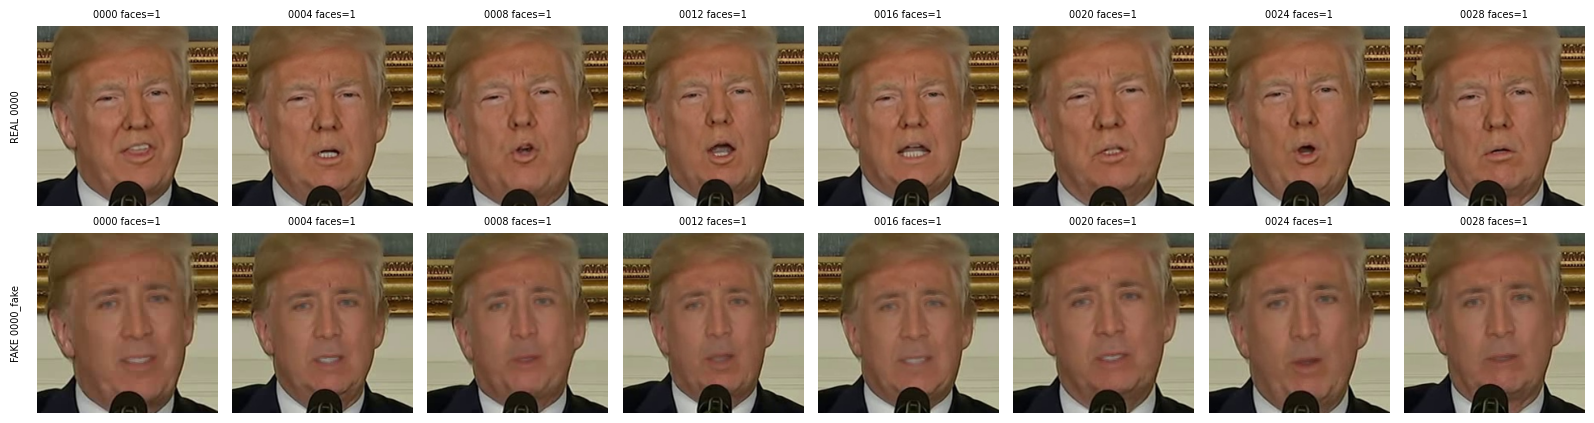

In [8]:
# 4.3 Smoke test
pair = sorted(set(videos.loc[videos.label == 0, "pair_id"]) & set(videos.loc[videos.label == 1, "pair_id"]))[0]
pick = videos[videos.pair_id == pair].sort_values("label").video_id.tolist()

t0 = time.time()
run_videos(pick)
print(f"{(time.time() - t0) / len(pick):.1f} s per video -> full run ~{(time.time() - t0) / len(pick) * len(videos) / 60:.1f} min (upper bound)")

fig, axes = plt.subplots(len(pick), 8, figsize=(16, 2.2 * len(pick)))
for row, vid in zip(axes, pick):
    crops = sorted(out_dir_of(vid).glob(f"*.{IMAGE_FORMAT}"))
    meta = load_boxes(vid) or {"n_faces": {}}
    for ax, c in zip(row, crops[::4]):
        ax.imshow(Image.open(c)); ax.axis("off")
        ax.set_title(f"{c.stem} faces={meta['n_faces'].get(str(int(c.stem)), '?')}", fontsize=7)
    row[0].text(-20, IMAGE_SIZE / 2, ("FAKE " if VIDEO.at[vid, "label"] else "REAL ") + vid[:28],
                rotation=90, va="center", ha="right", fontsize=7)
plt.tight_layout(); plt.show()

### 4.4 Full run

Resumable: if the session ends, rerun sections 1–3, 4.1, 4.2 and this cell. Finished videos are skipped. Real videos run first.

In [9]:
# 4.4 Full run
t0 = time.time()
order = videos.sort_values(["label", "video_id"]).video_id.tolist()
run_stats = run_videos(order)
print(f"took {(time.time() - t0) / 60:.1f} min")

videos: 100%|██████████| 98/98 [01:46<00:00,  1.09s/it]

{'skipped (done earlier)': 2, 'extracted': 96}
took 1.8 min


## 5. Extraction status

Expected: all 98 videos `done`, no failures. `frames with ≥2 faces` should be near zero (UADFV videos show one person).

In [10]:
# 5. Status
status_rows = []
for r in videos.itertuples():
    d = out_dir_of(r.video_id)
    state = "done" if (d / "_done").exists() else "failed" if (d / "_failed").exists() else "todo"
    meta = load_boxes(r.video_id) or {}
    nf = list(meta.get("n_faces", {}).values())
    status_rows.append({"video_id": r.video_id, "label": r.label, "pair_id": r.pair_id, "state": state,
                        "reason": (d / "_failed").read_text() if state == "failed" else "",
                        "missing_frames": int((d / "_done").read_text() or 0) if state == "done" else None,
                        "crops": len(list(d.glob(f"*.{IMAGE_FORMAT}"))) if d.exists() else 0,
                        "frames_no_face": sum(n == 0 for n in nf), "frames_multi_face": sum(n >= 2 for n in nf),
                        "frames_detected": len(nf)})
status = pd.DataFrame(status_rows)
status.to_csv(RUN_DIR / "extraction_status.csv", index=False)

print("state per class:")
display(status.groupby(["label", "state"]).size().unstack(fill_value=0))
failed = status[status.state == "failed"]
if len(failed):
    print("failed videos:"); display(failed[["video_id", "label", "reason"]])
done = status[status.state == "done"]
print(f"crops per done video: min {done.crops.min()}, median {done.crops.median():.0f}, max {done.crops.max()}")
print(f"frames without a face (box taken from nearest frame): {done.frames_no_face.sum()} of {done.frames_detected.sum()}")
print(f"frames with >= 2 confident faces: {done.frames_multi_face.sum()} of {done.frames_detected.sum()}")
worst = done.sort_values(["frames_no_face", "frames_multi_face"], ascending=False).head(5)
display(worst[["video_id", "label", "frames_no_face", "frames_multi_face"]])

state per class:


state,done
label,
0,49
1,49


crops per done video: min 32, median 32, max 32
frames without a face (box taken from nearest frame): 21 of 3136
frames with >= 2 confident faces: 99 of 3136


,video_id,label,frames_no_face,frames_multi_face
36,0036,0,4,0
85,0036_fake,1,4,0
5,0005,0,3,0
28,0028,0,3,0
54,0005_fake,1,3,0


## 6. Index CSV and summary

One row per crop. Columns: `label` (0 real, 1 fake), `video_id`, `pair_id` (real video and its fake share it), `frame_idx` (key 0–31), `src_frame` (decoded frame index), `n_faces`, `path` (relative to `faces_uadfv/`).

In [11]:
# 6.1 Build the index
rows = []
for r in videos[videos.video_id.isin(done.video_id)].itertuples():
    d = out_dir_of(r.video_id)
    meta = load_boxes(r.video_id)
    for c in sorted(d.glob(f"*.{IMAGE_FORMAT}")):
        k = str(int(c.stem))
        rows.append({"label": r.label, "video_id": r.video_id, "pair_id": r.pair_id, "frame_idx": int(k),
                     "src_frame": meta["frame_index"][k], "n_faces": meta["n_faces"][k],
                     "path": c.relative_to(FACES_ROOT).as_posix()})
index = pd.DataFrame(rows)
index.to_csv(INDEX_CSV, index=False)
print(f"saved {len(index):,} rows -> {INDEX_CSV}")
display(index.groupby("label").agg(videos=("video_id", "nunique"), crops=("path", "size")))

summary = {
    "videos_real": n_real, "videos_fake": n_fake,
    "other_entries": other,
    "done_real": int(((status.state == "done") & (status.label == 0)).sum()),
    "done_fake": int(((status.state == "done") & (status.label == 1)).sum()),
    "failed": failed[["video_id", "reason"]].to_dict("records"),
    "crops": int(len(index)),
    "frames_no_face": int(done.frames_no_face.sum()),
    "frames_multi_face_pct": round(100 * done.frames_multi_face.sum() / max(done.frames_detected.sum(), 1), 2),
    "resolutions": videos.assign(res=videos.width.astype(str) + "x" + videos.height.astype(str)).res.value_counts().to_dict(),
    "pipeline": PIPELINE,
}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

saved 3,136 rows -> /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/index/uadfv.csv


,videos,crops
label,,
0,49,1568
1,49,1568


{
  "videos_real": 49,
  "videos_fake": 49,
  "other_entries": {
    "real/real": [
      [
        "frames",
        "dir"
      ],
      [
        "landmarks",
        "dir"
      ]
    ],
    "fake/fake": [
      [
        "frames",
        "dir"
      ],
      [
        "landmarks",
        "dir"
      ]
    ]
  },
  "done_real": 49,
  "done_fake": 49,
  "failed": [],
  "crops": 3136,
  "frames_no_face": 21,
  "frames_multi_face_pct": 3.16,
  "resolutions": {
    "490x500": 8,
    "480x500": 4,
    "482x500": 4,
    "364x482": 4,
    "434x500": 4,
    "356x414": 2,
    "488x464": 2,
    "524x500": 2,
    "436x500": 2,
    "352x418": 2,
    "288x316": 2,
    "504x500": 2,
    "448x464": 2,
    "432x490": 2,
    "410x432": 2,
    "536x500": 2,
    "450x500": 2,
    "516x500": 2,
    "268x278": 2,
    "418x488": 2,
    "452x500": 2,
    "390x454": 2,
    "314x384": 2,
    "316x402": 2,
    "274x296": 2,
    "280x328": 2,
    "478x500": 2,
    "376x368": 2,
    "442x474": 2,
    "396x5

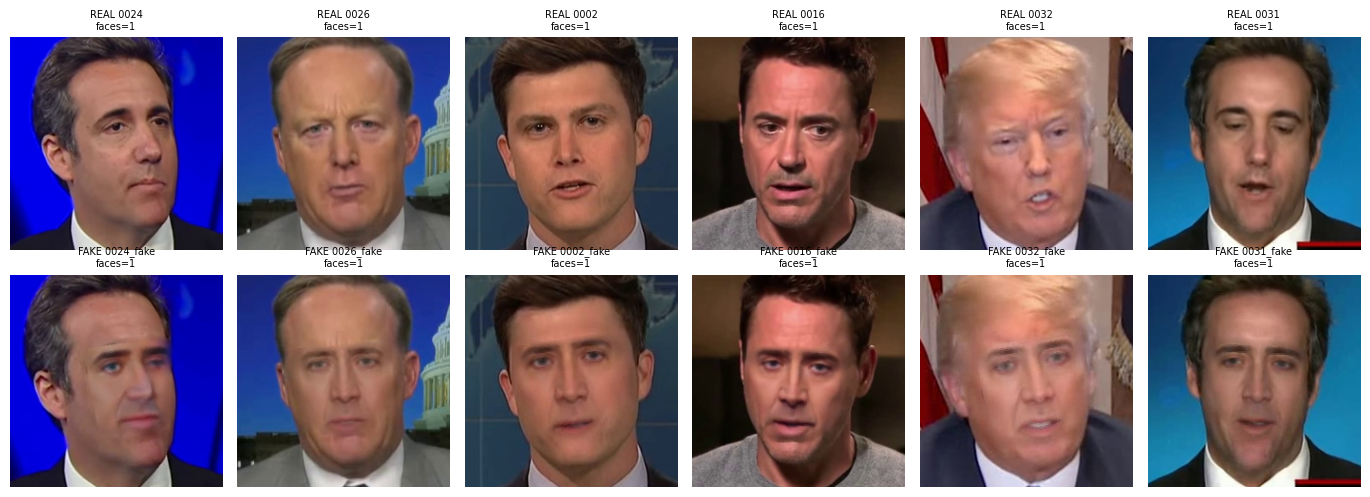

In [12]:
# 6.2 Example crops: 6 real videos and their fakes (frame 16)
pairs_done = sorted(set(index.loc[index.label == 0, "pair_id"]) & set(index.loc[index.label == 1, "pair_id"]))
show = random.Random(SEED).sample(pairs_done, min(6, len(pairs_done)))
fig, axes = plt.subplots(2, len(show), figsize=(2.3 * len(show), 5), squeeze=False)
for col, pid in enumerate(show):
    for row, label in enumerate((0, 1)):
        sub = index[(index.pair_id == pid) & (index.label == label)]
        r = sub.iloc[(sub.frame_idx - 16).abs().argmin()]
        ax = axes[row, col]
        ax.imshow(Image.open(FACES_ROOT / r.path)); ax.axis("off")
        ax.set_title(f"{'FAKE' if label else 'REAL'} {r.video_id}\nfaces={r.n_faces}", fontsize=7)
plt.tight_layout(); plt.show()